# Delivery-Time Regression

Predict purchase-to-delivery days for checkout estimates. Primary metric: MAE;
supporting metrics: RMSE and R². Success: beat Olist's estimate on final test MAE.

Predict at order placement after basket, sellers, destination and quotes are
confirmed, before payment approval. Delivery days include approval time.

## Setup

In [1]:
from pathlib import Path

# Support runs from the repo root or notebooks directory.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'Olist_data').is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run from the repository or its notebooks directory.')
DATA_DIR = PROJECT_ROOT / 'Olist_data'

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Data and Features

Use one row per delivered order, with postcode-median Haversine distances.
Valid delivery-day targets remain unchanged. Missing predictors are imputed
inside the pipeline. Canceled and undelivered orders are outside this cohort.

In [3]:
required_files = [
    'olist_orders_dataset.csv', 'olist_order_items_dataset.csv',
    'olist_products_dataset.csv', 'product_category_name_translation.csv',
    'olist_customers_dataset.csv', 'olist_sellers_dataset.csv',
    'olist_geolocation_dataset.csv'
]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing CSVs in {DATA_DIR}: {missing_files}')

orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
category_translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
customers = pd.read_csv(
    f"{DATA_DIR}/olist_customers_dataset.csv",
    dtype={'customer_zip_code_prefix': 'string'}
)
sellers = pd.read_csv(
    f"{DATA_DIR}/olist_sellers_dataset.csv",
    dtype={'seller_zip_code_prefix': 'string'}
)
geo = pd.read_csv(
    f"{DATA_DIR}/olist_geolocation_dataset.csv",
    dtype={'geolocation_zip_code_prefix': 'string'}
)

In [4]:
def haversine(lat1, lon1, lat2, lon2):
    """Calculate great-circle distance between two lat/lng points in kilometers."""
    earth_radius_km = 6371
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))
    return earth_radius_km * c


def mode_or_missing(series):
    """Return the most common non-missing value; break ties by pandas' sorted mode order."""
    mode_values = series.dropna().mode()
    if mode_values.empty:
        return np.nan
    return mode_values.iloc[0]


def iqr_outlier_bounds(series):
    """Return lower and upper outlier bounds using the 1.5 x IQR rule."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [5]:
def build_order_level_features(
    orders,
    order_items,
    products,
    category_translation,
    customers,
    sellers,
    geo,
    delivered_only=True
):
    orders = orders.copy()
    order_items = order_items.copy()
    products = products.copy()
    category_translation = category_translation.copy()
    customers = customers.copy()
    sellers = sellers.copy()
    geo = geo.copy()

    customers['customer_zip_code_prefix'] = customers['customer_zip_code_prefix'].astype('string').str.zfill(5)
    sellers['seller_zip_code_prefix'] = sellers['seller_zip_code_prefix'].astype('string').str.zfill(5)
    geo['geolocation_zip_code_prefix'] = geo['geolocation_zip_code_prefix'].astype('string').str.zfill(5)

    timestamp_columns = [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
    for column in timestamp_columns:
        if column in orders.columns:
            orders[column] = pd.to_datetime(orders[column], errors='coerce')
    order_items['shipping_limit_date'] = pd.to_datetime(
        order_items['shipping_limit_date'],
        errors='coerce'
    )

    products = products.merge(
        category_translation,
        on='product_category_name',
        how='left'
    )
    products['product_category_name_english'] = (
        products['product_category_name_english'].fillna('Unknown')
    )

    # Calculate volume of the product if dimensions exist
    if 'product_length_cm' in products.columns and 'product_height_cm' in products.columns and 'product_width_cm' in products.columns:
        products['product_volume_cm3'] = products['product_length_cm'] * products['product_height_cm'] * products['product_width_cm']

    # Calculate item physical score: weight * volume
    if 'product_weight_g' in products.columns and 'product_volume_cm3' in products.columns:
        products['item_physical_score'] = products['product_weight_g'] * products['product_volume_cm3']
    else:
        products['item_physical_score'] = np.nan

    df = order_items.merge(
        products[['product_id', 'product_category_name_english', 'product_weight_g', 'item_physical_score']],
        on='product_id',
        how='left'
    )
    df = df.merge(
        orders[[
            'order_id',
            'customer_id',
            'order_status',
            'order_purchase_timestamp',
            'order_delivered_customer_date',
            'order_estimated_delivery_date'
        ]],
        on='order_id',
        how='left'
    )

    if delivered_only:
        df = df[df['order_status'] == 'delivered'].copy()

    df = df.merge(
        customers[['customer_id', 'customer_state', 'customer_zip_code_prefix']],
        on='customer_id',
        how='left'
    )
    df = df.merge(
        sellers[['seller_id', 'seller_state', 'seller_zip_code_prefix']],
        on='seller_id',
        how='left'
    )

    geo_repeat_counts = geo['geolocation_zip_code_prefix'].value_counts()
    repeated_geo = geo[
        geo['geolocation_zip_code_prefix'].isin(geo_repeat_counts[geo_repeat_counts > 1].index)
    ].copy()
    geo_spread = (
        repeated_geo
        .groupby('geolocation_zip_code_prefix')
        .agg(
            min_lat=('geolocation_lat', 'min'),
            max_lat=('geolocation_lat', 'max'),
            min_lng=('geolocation_lng', 'min'),
            max_lng=('geolocation_lng', 'max')
        )
        .reset_index()
    )
    geo_spread['lat_range'] = geo_spread['max_lat'] - geo_spread['min_lat']
    geo_spread['lng_range'] = geo_spread['max_lng'] - geo_spread['min_lng']
    geo_spread['approx_coordinate_spread_km'] = haversine(
        geo_spread['min_lat'],
        geo_spread['min_lng'],
        geo_spread['max_lat'],
        geo_spread['max_lng']
    )

    outlier_columns = ['lat_range', 'lng_range', 'approx_coordinate_spread_km']
    outlier_mask = pd.Series(False, index=geo_spread.index)
    for column in outlier_columns:
        lower, upper = iqr_outlier_bounds(geo_spread[column])
        outlier_mask = outlier_mask | (geo_spread[column] < lower) | (geo_spread[column] > upper)
    geo_outlier_zips = set(geo_spread.loc[outlier_mask, 'geolocation_zip_code_prefix'])

    geo_by_zip = (
        geo.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(
               latitude=('geolocation_lat', 'median'),
               longitude=('geolocation_lng', 'median')
           )
    )
    df = df.merge(
        geo_by_zip.rename(columns={
            'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
            'latitude': 'customer_lat',
            'longitude': 'customer_lng'
        }),
        on='customer_zip_code_prefix',
        how='left'
    )
    df = df.merge(
        geo_by_zip.rename(columns={
            'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
            'latitude': 'seller_lat',
            'longitude': 'seller_lng'
        }),
        on='seller_zip_code_prefix',
        how='left'
    )
    df['seller_buyer_distance_km'] = haversine(
        df['customer_lat'],
        df['customer_lng'],
        df['seller_lat'],
        df['seller_lng']
    )

    df['delivery_days'] = (
        df['order_delivered_customer_date'] - df['order_purchase_timestamp']
    ).dt.total_seconds() / (24 * 60 * 60)
    # Olist's checkout promise is benchmark-only.
    df['olist_estimated_delivery_days'] = (
        df['order_estimated_delivery_date'] - df['order_purchase_timestamp']
    ).dt.total_seconds() / (24 * 60 * 60)
    df['purchase_month'] = df['order_purchase_timestamp'].dt.month
    df['purchase_day_of_week'] = df['order_purchase_timestamp'].dt.day_name()
    df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour

    # New is_weekend feature
    df['is_weekend'] = df['order_purchase_timestamp'].dt.dayofweek.isin([5, 6]).astype(str)

    # New is_interstate feature
    df['is_interstate'] = (df['customer_state'] != df['seller_state']).astype(str)

    df['shipping_deadline_days'] = (
        df['shipping_limit_date'] - df['order_purchase_timestamp']
    ).dt.total_seconds() / (24 * 60 * 60)

    farthest_seller_state_by_order = (
        df.sort_values(
            ['order_id', 'seller_buyer_distance_km'],
            ascending=[True, False]
        )
        .drop_duplicates('order_id')
        [['order_id', 'seller_state']]
        .rename(columns={'seller_state': 'farthest_seller_state'})
    )

    df_order = (
        df.groupby('order_id', as_index=False)
          .agg(
              delivery_days=('delivery_days', 'first'),
              order_purchase_timestamp=('order_purchase_timestamp', 'first'),
              order_delivered_customer_date=('order_delivered_customer_date', 'first'),
              olist_estimated_delivery_days=('olist_estimated_delivery_days', 'first'),
              customer_state=('customer_state', 'first'),
              purchase_month=('purchase_month', 'first'),
              purchase_day_of_week=('purchase_day_of_week', 'first'),
              purchase_hour=('purchase_hour', 'first'),
              is_weekend=('is_weekend', 'first'),
              is_interstate=('is_interstate', 'first'),
              n_items=('order_item_id', 'size'),
              n_unique_products=('product_id', 'nunique'),
              n_product_categories=('product_category_name_english', 'nunique'),
              main_product_category=('product_category_name_english', mode_or_missing),
              total_price=('price', 'sum'),
              total_freight=('freight_value', 'sum'),
              total_product_weight_g=('product_weight_g', 'sum'),
              max_product_weight_g=('product_weight_g', 'max'),
              total_physical_score=('item_physical_score', 'sum'),
              n_sellers=('seller_id', 'nunique'),
              n_seller_states=('seller_state', 'nunique'),
              max_seller_buyer_distance_km=('seller_buyer_distance_km', 'max'),
              max_shipping_deadline_days=('shipping_deadline_days', 'max')
          )
    )

    df_order = df_order.merge(
        farthest_seller_state_by_order,
        on='order_id',
        how='left'
    )

    df_order['freight_ratio'] = (
        df_order['total_freight'] / (df_order['total_price'] + 1)
    )

    metadata = {
        'item_rows_after_filter': len(df),
        'order_rows': len(df_order),
        'geo_outlier_zip_count': len(geo_outlier_zips),
        'distance_coverage': df_order['max_seller_buyer_distance_km'].notna().mean()
    }
    return df_order, metadata

In [6]:
df_order, feature_metadata = build_order_level_features(
    orders=orders,
    order_items=order_items,
    products=products,
    category_translation=category_translation,
    customers=customers,
    sellers=sellers,
    geo=geo,
    delivered_only=True
)
df_model = df_order.copy()

## Checkout Predictors

| Inputs | Available source / assumption |
|---|---|
| `n_items`, `n_unique_products`, `n_product_categories`, `n_sellers`, `n_seller_states` | Confirmed basket, catalog categories and assigned sellers. |
| `total_freight`, `freight_ratio` | Checkout freight quotes and item prices, not actual transport costs. |
| `total_product_weight_g`, `total_physical_score` | Catalog weights/dimensions, not measured packed parcels. |
| `max_seller_buyer_distance_km`, `farthest_seller_state` | Checkout addresses and an existing postcode reference. |
| `is_interstate` | Buyer/seller states of the first item, as currently aggregated. |
| `main_product_category` | Most frequent basket category. |
| `purchase_month`, `purchase_day_of_week`, `purchase_hour`, `is_weekend` | Purchase timestamp. |

**Assumption:** recorded quotes, catalog values, seller assignments and addresses
match checkout snapshots; the CSVs lack history to verify this. Geography must
also be available then. Approval/delivery events, final status, reviews and IDs
are not inputs. Delivered status selects the labeled cohort only; results do not
cover canceled or undelivered orders. Olist's estimate is benchmark-only.

## Evaluation Design

Assign cohorts by purchase date: train before May 2018, validate in May–June,
and reserve July onward for testing. Keep validation/test orders even when
delivery occurs after their purchase window. Training and CV fits use only
labels available at their historical cutoff.

Use the same five expanding-window folds for screening and tuning; fit
preprocessing separately inside each fold.

### Team Review: Prof Points 3, 4 and 6

Purchase dates define the cohorts; late completion does not exclude validation
orders. Preserve label-availability checks for training and report split sizes.

In [7]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    'n_items',
    'n_unique_products',
    'n_product_categories',
    'n_sellers',
    'n_seller_states',
    'total_freight',
    'total_product_weight_g',
    'total_physical_score',
    'max_seller_buyer_distance_km',
    'freight_ratio'
]

categorical_features = [
    'purchase_month',
    'purchase_day_of_week',
    'purchase_hour',
    'main_product_category',
    'farthest_seller_state',
    'is_weekend',
    'is_interstate'
]


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

def make_preprocessor(categorical_feature_list):
    return ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_feature_list)
        ]
    )

preprocessor = make_preprocessor(categorical_features)

feature_columns = numeric_features + categorical_features

# Revise the availability audit whenever this input list changes.
CHECKOUT_FEATURES = {
    'n_items', 'n_unique_products', 'n_product_categories', 'n_sellers',
    'n_seller_states', 'total_freight', 'total_product_weight_g',
    'total_physical_score', 'max_seller_buyer_distance_km', 'freight_ratio',
    'purchase_month', 'purchase_day_of_week', 'purchase_hour',
    'main_product_category', 'farthest_seller_state', 'is_weekend', 'is_interstate'
}
assert len(feature_columns) == len(set(feature_columns)), 'Duplicate inputs.'
assert set(feature_columns) == CHECKOUT_FEATURES, 'Update the checkout feature audit.'


# Keep the promise outside all model inputs.
BENCHMARK_COL = 'olist_estimated_delivery_days'
assert not set(feature_columns).intersection({
    BENCHMARK_COL, 'promised_days', 'estimated_delivery_days',
    'order_estimated_delivery_date', 'delivery_days'
})
META_COLS = ['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date']
assert not set(feature_columns).intersection(META_COLS)
modeling_data = df_model.dropna(subset=['delivery_days', BENCHMARK_COL] + META_COLS).copy()
valid_target = np.isfinite(modeling_data['delivery_days']) & modeling_data['delivery_days'].ge(0)
modeling_data = modeling_data.loc[valid_target].sort_values(
    ['order_purchase_timestamp', 'order_id'], kind='stable'
).copy()
assert modeling_data['order_id'].is_unique

VALIDATION_START = pd.Timestamp('2018-05-01')
TEST_START = pd.Timestamp('2018-07-01')
purchase_time = modeling_data['order_purchase_timestamp']
train_period = modeling_data.loc[purchase_time < VALIDATION_START].copy()
validation_period = modeling_data.loc[
    purchase_time.ge(VALIDATION_START) & purchase_time.lt(TEST_START)
].copy()
test_df = modeling_data.loc[purchase_time >= TEST_START].copy()
train_df = train_period.loc[train_period['order_delivered_customer_date'] < VALIDATION_START].copy()
validation_df = validation_period.copy()
assert all(len(part) > 0 for part in [train_df, validation_df, test_df])
assert train_df['order_purchase_timestamp'].max() < validation_df['order_purchase_timestamp'].min()
assert validation_df['order_purchase_timestamp'].max() < test_df['order_purchase_timestamp'].min()
assert train_df['order_delivered_customer_date'].max() < VALIDATION_START
assert len(train_period) + len(validation_period) + len(test_df) == len(modeling_data)
assert validation_df['order_id'].equals(validation_period['order_id'])
assert set(train_df['order_id']).isdisjoint(validation_df['order_id'])
assert set(train_df['order_id']).isdisjoint(test_df['order_id'])
assert set(validation_df['order_id']).isdisjoint(test_df['order_id'])

X_train = train_df[feature_columns].copy()
X_validation = validation_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
y_regression_train = train_df['delivery_days'].copy()
y_regression_validation = validation_df['delivery_days'].copy()
y_regression_test = test_df['delivery_days'].copy()
olist_validation_predictions = validation_df[BENCHMARK_COL].copy()
olist_test_predictions = test_df[BENCHMARK_COL].copy()
for features, target in [(X_train, y_regression_train), (X_validation, y_regression_validation), (X_test, y_regression_test)]:
    assert features.index.equals(target.index)
    assert BENCHMARK_COL not in features.columns

split_summary = pd.DataFrame([
    {
        'Split': name, 'Period orders': len(period), 'Usable orders': len(used),
        'Excluded at training cutoff': len(period) - len(used),
        'First purchase used': used['order_purchase_timestamp'].min(),
        'Last purchase used': used['order_purchase_timestamp'].max()
    }
    for name, period, used in [
        ('Train', train_period, train_df),
        ('Validation', validation_period, validation_df),
        ('Test (reserved)', test_df, test_df)
    ]
])
display(split_summary)

,Split,Period orders,Usable orders,Excluded at training cutoff,First purchase used,Last purchase used
0,Train,71118,68318,2800,2016-09-15 12:16:38,2018-04-27 13:06:08
1,Validation,12845,12845,0,2018-05-01 00:02:11,2018-06-30 23:59:49
2,Test (reserved),12507,12507,0,2018-07-01 00:25:07,2018-08-29 15:00:37


In [8]:
# Expanding windows with training labels known before each validation window.
cv_splitter = TimeSeriesSplit(n_splits=5)
cv_folds, fold_rows = [], []
purchase_times = train_df['order_purchase_timestamp']
delivery_times = train_df['order_delivered_customer_date']
for fold, (candidate_train, valid_pos) in enumerate(cv_splitter.split(X_train), 1):
    valid_start = purchase_times.iloc[valid_pos].min()
    known = (purchase_times.iloc[candidate_train].lt(valid_start)
             & delivery_times.iloc[candidate_train].lt(valid_start)).to_numpy()
    train_pos = candidate_train[known]
    assert len(train_pos) > 0, 'Insufficient completed orders for this fold.'
    assert purchase_times.iloc[train_pos].max() < valid_start
    assert delivery_times.iloc[train_pos].max() < valid_start
    cv_folds.append((train_pos, valid_pos))
    fold_rows.append({
        'Fold': fold, 'Train orders': len(train_pos), 'Validation orders': len(valid_pos),
        'Unavailable labels / boundary ties': len(candidate_train) - len(train_pos),
        'Train start': purchase_times.iloc[train_pos].min(),
        'Train end': purchase_times.iloc[train_pos].max(),
        'Validation start': valid_start,
        'Validation end': purchase_times.iloc[valid_pos].max()
    })
cv_fold_summary = pd.DataFrame(fold_rows)

## Candidate Models

| Candidate | Purpose |
|---|---|
| Mean/median benchmarks | No-feature reference; median aligns with MAE. |
| Linear Regression, Ridge, Lasso | Simple linear relationships and regularisation. |
| Decision Tree, Random Forest | Nonlinear thresholds and interactions. |
| Gradient boosting: squared, absolute, Huber | Matched loss comparison with long deliveries retained. |

Screen both families before tuning. MAE is primary; fit time, variability and
complexity inform close decisions. Absolute/Huber losses reduce sensitivity to
extreme errors but do not guarantee better tail predictions.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def model_pipeline(model):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', model)])

candidate_models = {
    'Mean benchmark': DummyRegressor(strategy='mean'),
    'Median benchmark': DummyRegressor(strategy='median'),
    'Linear Regression': model_pipeline(LinearRegression()),
    'Ridge': model_pipeline(Ridge(alpha=1.0)),
    'Lasso': model_pipeline(Lasso(alpha=1.0, max_iter=5000, random_state=42)),
    'Decision Tree': model_pipeline(DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=42)),
    'Random Forest': model_pipeline(RandomForestRegressor(
        n_estimators=100, max_depth=16, min_samples_leaf=20, random_state=42, n_jobs=-1
    ))
}
linear_names = {'Linear Regression', 'Ridge', 'Lasso'}
for name, loss in [('Boosting (squared)', 'squared_error'),
                   ('Boosting (absolute)', 'absolute_error'), ('Boosting (Huber)', 'huber')]:
    candidate_models[name] = model_pipeline(GradientBoostingRegressor(
        loss=loss, n_estimators=100, learning_rate=0.05, max_depth=3,
        min_samples_leaf=20, alpha=0.9, random_state=42
    ))
model_families = {
    name: 'Benchmark' if 'benchmark' in name else 'Linear' if name in linear_names else 'Tree'
    for name in candidate_models
}
assert y_regression_train.equals(train_df['delivery_days'])

## Initial Screening

Compare initial settings on identical temporal folds. Lower MAE/RMSE and higher
R² are better. Fit times cover all five folds on this machine.

In [10]:
scoring = {'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error', 'R2': 'r2'}
screening_rows, screening_scores = [], {}
for name, model in candidate_models.items():
    scores = cross_validate(
        model, X_train, y_regression_train, cv=cv_folds, scoring=scoring,
        n_jobs=1, error_score='raise'
    )
    screening_scores[name] = scores
    mae, rmse = -scores['test_MAE'], np.sqrt(-scores['test_MSE'])
    screening_rows.append({
        'Model': name, 'Family': model_families[name],
        'CV MAE': mae.mean(), 'MAE std': mae.std(),
        'CV RMSE': rmse.mean(), 'CV R2': scores['test_R2'].mean(),
        'CV fit seconds': scores['fit_time'].sum()
    })
screening_results = pd.DataFrame(screening_rows).sort_values(['CV MAE', 'Model'])
display(screening_results.round(3))

,Model,Family,CV MAE,MAE std,CV RMSE,CV R2,CV fit seconds
8,Boosting (absolute),Tree,5.505,1.125,8.718,0.098,23.123
9,Boosting (Huber),Tree,5.578,0.964,8.626,0.115,24.145
6,Random Forest,Tree,5.745,0.707,8.618,0.108,26.442
7,Boosting (squared),Tree,5.760,0.742,8.624,0.106,21.949
4,Lasso,Linear,5.822,0.975,8.657,0.107,0.915
5,Decision Tree,Tree,5.850,0.615,8.734,0.081,1.613
1,Median benchmark,Benchmark,6.486,1.203,9.662,-0.112,0.012
0,Mean benchmark,Benchmark,6.497,1.016,9.333,-0.041,0.014
3,Ridge,Linear,7.039,1.362,9.892,-0.272,0.822
2,Linear Regression,Linear,7.898,2.101,11.176,-0.778,1.053


## Shortlist and Tune

Shortlist the lowest-CV-MAE candidate from each family. Tune only these candidates
with six sampled configurations, the same five folds and seed 42. Ordinary
Linear Regression has no search here. Search spaces are defined below.

In [11]:
shortlist = (
    screening_results.loc[screening_results['Family'].ne('Benchmark')]
    .sort_values(['CV MAE', 'Model']).groupby('Family', sort=False).head(1)
)
shortlisted_names = shortlist['Model'].tolist()
display(shortlist[['Model', 'Family', 'CV MAE', 'MAE std']].round(3))

,Model,Family,CV MAE,MAE std
8,Boosting (absolute),Tree,5.505,1.125
4,Lasso,Linear,5.822,0.975


In [12]:
from sklearn.model_selection import RandomizedSearchCV

parameter_spaces = {
    'Ridge': {'model__alpha': np.logspace(-3, 3, 20)},
    'Lasso': {'model__alpha': np.logspace(-5, 0, 20)},
    'Decision Tree': {
        'model__max_depth': [6, 10, 16], 'model__min_samples_leaf': [10, 20, 50],
        'model__min_samples_split': [20, 100, 200]
    },
    'Random Forest': {
        'model__n_estimators': [50, 100, 150], 'model__max_depth': [10, 15, 20],
        'model__min_samples_leaf': [10, 20, 50], 'model__max_features': ['sqrt', 0.8, 1.0]
    }
}
boosting_space = {
    'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3], 'model__min_samples_leaf': [20, 50]
}
for name in candidate_models:
    if name.startswith('Boosting'):
        parameter_spaces[name] = dict(boosting_space)
parameter_spaces['Boosting (Huber)']['model__alpha'] = [0.85, 0.9, 0.95]

searches, tuning_rows = {}, []
for name in shortlisted_names:
    if name not in parameter_spaces:
        continue
    search = RandomizedSearchCV(
        clone(candidate_models[name]), parameter_spaces[name], n_iter=6,
        cv=cv_folds, scoring='neg_mean_absolute_error', random_state=42,
        n_jobs=1, refit=True, error_score='raise'
    )
    search.fit(X_train, y_regression_train)
    searches[name] = search
    initial_mae = screening_results.set_index('Model').loc[name, 'CV MAE']
    tuning_rows.append({
        'Model': name, 'Initial CV MAE': initial_mae,
        'Tuned CV MAE': -search.best_score_,
        'MAE improvement': initial_mae + search.best_score_,
        'Best parameters': search.best_params_
    })
tuning_results = pd.DataFrame(tuning_rows)

In [13]:
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(tuning_results.round(3))


,Model,Initial CV MAE,Tuned CV MAE,MAE improvement,Best parameters
0,Boosting (absolute),5.505,5.472,0.033,"{'model__n_estimators': 100, 'model__min_samples_leaf': 20, 'model__max_depth': 2, 'model__learning_rate': 0.05}"
1,Lasso,5.822,5.492,0.329,{'model__alpha': 0.08858667904100823}


## Validation Comparison

Compare shortlisted initial/tuned candidates and benchmarks on all May–June
purchase orders. Tuning is not assumed to help. Prediction timings are
approximate, not production benchmarks.

### Team Review: Prof Point 10

*Adapted from Prof Prakash: use Olist's estimate as the benchmark, not as an
input to the replacement regressor.*

In [14]:
from time import perf_counter

def regression_metrics(actual, predicted):
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted)
    }

validation_models = {}
for name in ['Mean benchmark', 'Median benchmark'] + shortlisted_names:
    fitted = clone(candidate_models[name]).fit(X_train, y_regression_train)
    validation_models[f'{name} (initial)'] = fitted
    if name in searches:
        validation_models[f'{name} (tuned)'] = searches[name].best_estimator_

validation_rows, validation_predictions = [], {}
for name, fitted in validation_models.items():
    start = perf_counter()
    predicted = fitted.predict(X_validation)
    elapsed = perf_counter() - start
    validation_predictions[name] = predicted
    row = {'Model': name, 'Train MAE': mean_absolute_error(
        y_regression_train, fitted.predict(X_train)
    )}
    row.update(regression_metrics(y_regression_validation, predicted))
    row['Prediction ms/order'] = 1000 * elapsed / len(X_validation)
    validation_rows.append(row)

# Benchmark Olist's unchanged checkout estimate.
assert olist_validation_predictions.index.equals(y_regression_validation.index)
validation_rows.append({
    'Model': 'Olist checkout estimate',
    **regression_metrics(y_regression_validation, olist_validation_predictions)
})
validation_results = pd.DataFrame(validation_rows).sort_values(['MAE', 'Model'])
display(validation_results.round(3))

,Model,Train MAE,MAE,RMSE,R2,Prediction ms/order
2,Boosting (absolute) (initial),5.067,4.335,6.442,0.254,0.003
3,Boosting (absolute) (tuned),5.157,4.379,6.437,0.255,0.003
5,Lasso (tuned),5.459,4.979,6.707,0.191,0.001
1,Median benchmark (initial),6.332,5.533,7.506,-0.013,0.000
4,Lasso (initial),5.913,5.777,7.261,0.052,0.001
0,Mean benchmark (initial),6.591,6.463,8.061,-0.168,0.000
6,Olist checkout estimate,NaN,15.531,17.936,-4.784,NaN


## Finalist Stability

Compare identical temporal folds and fixed settings. Seed SD measures algorithm
randomness; fold SD measures variation across periods. Cyclic Lasso is
deterministic, so only one run is needed and seed SD is not applicable.

### Team Review: Prof Point 8

Compare MAE and variability before preferring complexity; the old 0.06-day seed
result is not transferable to this evaluation. These are finalists, not a frozen champion.

In [15]:
SEEDS = [42, 101, 2023, 777, 999]
finalists = {
    'Boosting absolute (initial)': validation_models['Boosting (absolute) (initial)'],
    'Lasso (tuned)': validation_models['Lasso (tuned)']
}
stability_rows, temporal_rows = [], []
for name, fitted in finalists.items():
    deterministic = (isinstance(fitted.named_steps['model'], Lasso)
                     and fitted.named_steps['model'].selection == 'cyclic')
    seeds = [42] if deterministic else SEEDS
    for seed in seeds:
        model = fitted
        if seed == 42:
            if deterministic:
                search = searches['Lasso']
                fold_mae = np.array([
                    -search.cv_results_[f'split{i}_test_score'][search.best_index_]
                    for i in range(len(cv_folds))
                ])
            else:
                fold_mae = -screening_scores['Boosting (absolute)']['test_MAE']
        else:
            model = clone(fitted).set_params(model__random_state=seed)
            scores = cross_validate(
                model, X_train, y_regression_train, cv=cv_folds,
                scoring='neg_mean_absolute_error', n_jobs=1, error_score='raise'
            )
            fold_mae = -scores['test_score']
            model.fit(X_train, y_regression_train)
        stability_rows.append({
            'Model': name, 'Seed': seed, 'CV MAE': fold_mae.mean(),
            'Validation MAE': mean_absolute_error(y_regression_validation, model.predict(X_validation))
        })
        temporal_rows.extend({'Model': name, 'Seed': seed, 'Fold': fold + 1, 'MAE': mae}
                             for fold, mae in enumerate(fold_mae))
stability_runs = pd.DataFrame(stability_rows)
temporal_runs = pd.DataFrame(temporal_rows)
fold_comparison = temporal_runs.groupby(['Fold', 'Model'])['MAE'].mean().unstack('Model')
stability_summary = stability_runs.groupby('Model').agg(
    seed_runs=('Seed', 'size'), cv_mae=('CV MAE', 'mean'),
    cv_seed_sd=('CV MAE', 'std'), validation_mae=('Validation MAE', 'mean'),
    validation_seed_sd=('Validation MAE', 'std')
)
stability_summary['temporal_fold_sd'] = fold_comparison.std(ddof=0)
display(stability_summary.round(4))
display(fold_comparison.round(3))

,seed_runs,cv_mae,cv_seed_sd,validation_mae,validation_seed_sd,temporal_fold_sd
Model,,,,,,
Boosting absolute (initial),5,5.502,0.003,4.337,0.001,1.128
Lasso (tuned),1,5.492,NaN,4.979,NaN,0.862


Model,Boosting absolute (initial),Lasso (tuned)
Fold,,
1,4.001,4.565
2,4.565,4.506
3,6.950,6.646
4,6.565,6.233
5,5.428,5.513


Boosting is stable across the tested seeds; cyclic Lasso is deterministic.
The fold table averages boosting over five seeds and uses one Lasso fit per
fold. Both models use identical temporal folds.

Lasso wins folds 2-4, and mean CV MAEs are nearly tied. Boosting is selected
for its lower validation MAE, not consistent superiority across periods.
These results support training repeatability, but not broad robustness or
improved robustness from tuning. Temporal sensitivity remains a limitation.

## Validation Feature Importance

Shuffle each raw feature on the same fixed sample of up to 5,000 validation orders. Larger MAE increases indicate greater reliance. Correlated inputs may share importance; shuffle SD is not a confidence interval. Month importance does not prove seasonality. Feature changes require another training-CV comparison.

### Team Review: Prof Points 3 and 14

Use held-out permutation importance, not MDI; recheck `purchase_month` after temporal splitting.

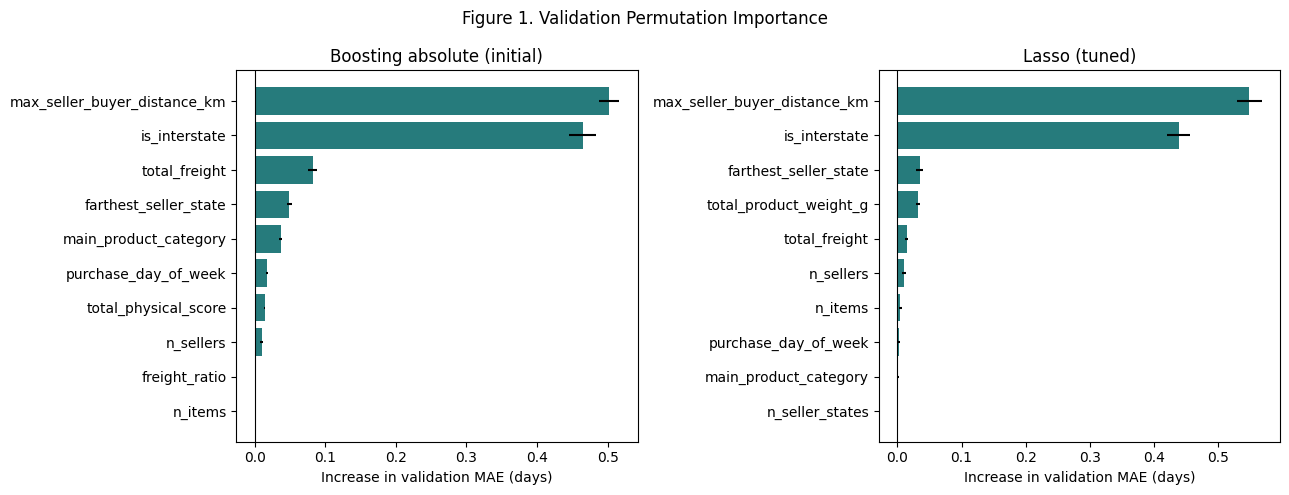

,Model,Feature,Rank,MAE increase,Shuffle SD
16,Boosting absolute (initial),purchase_month,17,-0.063,0.003
30,Lasso (tuned),purchase_month,14,0.000,0.000


In [16]:
from sklearn.inspection import permutation_importance

importance_X = X_validation.sample(n=min(5000, len(X_validation)), random_state=42)
importance_y = y_regression_validation.loc[importance_X.index]
importance_rows = []
for name, model in finalists.items():
    result = permutation_importance(
        model, importance_X, importance_y, scoring='neg_mean_absolute_error',
        n_repeats=10, random_state=42, n_jobs=1
    )
    frame = pd.DataFrame({
        'Model': name, 'Feature': feature_columns,
        'MAE increase': result.importances_mean, 'Shuffle SD': result.importances_std
    }).sort_values('MAE increase', ascending=False)
    frame['Rank'] = np.arange(1, len(frame) + 1)
    importance_rows.append(frame)
permutation_results = pd.concat(importance_rows, ignore_index=True)

fig, axes = plt.subplots(1, len(finalists), figsize=(13, 5), squeeze=False)
for ax, (name, frame) in zip(axes.flat, permutation_results.groupby('Model', sort=False)):
    top = frame.head(10).sort_values('MAE increase')
    ax.barh(top['Feature'], top['MAE increase'], xerr=top['Shuffle SD'], color='#267b7c')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(title=name, xlabel='Increase in validation MAE (days)')
fig.suptitle('Figure 1. Validation Permutation Importance')
plt.tight_layout()
plt.show()
display(permutation_results.loc[permutation_results['Feature'].eq('purchase_month'),
        ['Model', 'Feature', 'Rank', 'MAE increase', 'Shuffle SD']].round(4))

## Month Ablation

Refit each finalist without month, keeping settings, seed 42 and folds fixed.
Negative MAE changes favour removal. Review CV and validation together;
permutation importance alone does not justify dropping a feature.

### Team Review: Prof Points 3 and 14

Test month removal with identical temporal folds after inspecting held-out importance.

In [17]:
month_ablation_models, month_rows = {}, []
for name, original in finalists.items():
    for keep_month in [True, False]:
        label = 'With month' if keep_month else 'Without month'
        columns = feature_columns if keep_month else [c for c in feature_columns if c != 'purchase_month']
        model = original
        if keep_month:
            fold_mae = temporal_runs.loc[
                temporal_runs['Model'].eq(name) & temporal_runs['Seed'].eq(42)
            ].sort_values('Fold')['MAE'].to_numpy()
            assert len(fold_mae) == len(cv_folds)
        else:
            model = clone(original)
            prep = model.named_steps['preprocess']
            prep.set_params(transformers=[
                (key, transformer, [c for c in selected if c != 'purchase_month'])
                for key, transformer, selected in prep.transformers
            ])
            scores = cross_validate(
                model, X_train[columns], y_regression_train, cv=cv_folds,
                scoring='neg_mean_absolute_error', n_jobs=1, error_score='raise'
            )
            fold_mae = -scores['test_score']
            model.fit(X_train[columns], y_regression_train)
        predicted = model.predict(X_validation[columns])
        month_ablation_models[(name, label)] = model
        month_rows.append({
            'Model': name, 'Features': label,
            'CV MAE': fold_mae.mean(), 'Fold SD': fold_mae.std(),
            'Validation MAE': mean_absolute_error(y_regression_validation, predicted),
            'Validation RMSE': np.sqrt(mean_squared_error(y_regression_validation, predicted)),
            'Validation R2': r2_score(y_regression_validation, predicted)
        })
month_ablation_results = pd.DataFrame(month_rows)
for metric in ['CV MAE', 'Validation MAE']:
    reference = month_ablation_results.loc[month_ablation_results['Features'].eq('With month')].set_index('Model')[metric]
    month_ablation_results[f'Change in {metric}'] = (
        month_ablation_results[metric] - month_ablation_results['Model'].map(reference)
    )
display(month_ablation_results.round(4))

,Model,Features,CV MAE,Fold SD,Validation MAE,Validation RMSE,Validation R2,Change in CV MAE,Change in Validation MAE
0,Boosting absolute (initial),With month,5.505,1.125,4.335,6.442,0.254,0.000,0.000
1,Boosting absolute (initial),Without month,5.333,1.150,4.412,6.381,0.268,-0.172,0.077
2,Lasso (tuned),With month,5.492,0.862,4.979,6.707,0.191,0.000,0.000
3,Lasso (tuned),Without month,5.447,0.911,5.415,6.993,0.121,-0.045,0.436


Removing month improves CV MAE but worsens validation MAE for both finalists.
Retain it for the current validation-led selection; this does not establish seasonality.

## Freeze the Model

Select initial absolute-error boosting with all 17 features, including month,
using validation MAE and seed stability. Keep its training fit unchanged.

### Team Review: Prof Point 7

Make all model and feature decisions using training CV and validation; evaluate the frozen model once on test.

In [18]:
from sklearn.utils.validation import check_is_fitted

selected_model_name = 'Boosting absolute (initial)'
selected_regression_model = month_ablation_models[(selected_model_name, 'With month')]
check_is_fitted(selected_regression_model.named_steps['model'])
assert list(selected_regression_model.feature_names_in_) == feature_columns
selected_feature_columns = tuple(feature_columns)


## Final Test

Evaluate the frozen model once against Olist on the same reserved orders.

### Team Review: Prof Points 7, 8 and 10

Freeze by validation MAE, then test once. *Adapted from Prof Prakash's comment:
when replacing Olist's checkout estimate, exclude it as an input and benchmark
its MAE against actual delivery days.*

In [19]:
# Frozen before inspecting test results; do not tune on this cohort.
assert olist_test_predictions.index.equals(y_regression_test.index)
assert X_test.index.equals(y_regression_test.index)
assert list(X_test.columns) == list(selected_feature_columns)
final_test_predictions = selected_regression_model.predict(X_test)
final_test_results = pd.DataFrame([
    {'Model': selected_model_name,
     **regression_metrics(y_regression_test, final_test_predictions)},
    {'Model': 'Olist checkout estimate',
     **regression_metrics(y_regression_test, olist_test_predictions)}
])
display(final_test_results.round(3))
print(f'Test orders: {len(X_test):,}')
print('Success criterion (lower MAE than Olist):',
      final_test_results.iloc[0]['MAE'] < final_test_results.iloc[1]['MAE'])


,Model,MAE,RMSE,R2
0,Boosting absolute (initial),3.915,5.158,0.078
1,Olist checkout estimate,9.722,12.091,-4.067


Test orders: 12,507
Success criterion (lower MAE than Olist): True


### Final Selection

Retain initial absolute-error boosting, selected using validation MAE before
testing. On 12,507 test orders, MAE is 3.915 days versus Olist's 9.722
(59.7% lower), meeting the MAE success criterion. RMSE is 5.158 days and
R² is 0.078, so explained variation remains modest.

Olist's estimate is a promise, not necessarily an MAE-optimal forecast;
lower MAE does not establish equivalent service-level coverage.

## Limitations

Retrospective snapshots cannot prove checkout availability. Training-label
cutoffs underrepresent slow unresolved orders; validation/test retain all
observed deliveries in their purchase cohorts. Full validation outcomes arrive
after the test period starts, so this is retrospective cohort evaluation, not
a complete replay of model selection at July checkout.

Under two years cannot establish seasonality; month may identify a historical
period. Remote-state samples are sparse and distances approximate routes.
Temporal scores are not comparable with random splits. Previously consulted
test orders are not fresh. Search-CV scores are not independent of tuning.

Boosting is validation-selected, not consistently superior across time: Lasso
wins several temporal folds, and mean CV MAEs are nearly tied. Boosting's small seed variation measures training
repeatability, not robustness to changing periods. Its validation advantage
may not persist; simpler Lasso remains a credible alternative.

## Winning Model for FastAPI

Save the frozen pipeline and input schema. It includes fitted imputation,
scaling, one-hot encoding and regression. Inputs are the 17 engineered order-level
features, not raw CSV rows. The API must reproduce the checkout feature builder.
Load only trusted joblib files, using the recorded package versions.

In [20]:
import joblib
import platform
import sklearn

winning_model = selected_regression_model
winning_model_bundle = {
    'pipeline': winning_model,
    'model_name': selected_model_name,
    'feature_columns': list(selected_feature_columns),
    'feature_dtypes': X_train[list(selected_feature_columns)].dtypes.astype(str).to_dict(),
    'target': 'delivery_days',
    'prediction_point': 'Order placement, before payment approval',
    'training_purchase_cutoff': '2018-05-01',
    'training_label_cutoff': '2018-05-01',
    'input_stage': 'Engineered order-level checkout features',
    'versions': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__, 'joblib': joblib.__version__}
}
artifact_dir = PROJECT_ROOT / 'artifacts'
artifact_dir.mkdir(exist_ok=True)
model_path = artifact_dir / 'delivery_regression.joblib'
joblib.dump(winning_model_bundle, model_path)

# Round-trip check for the future API loader.
loaded_bundle = joblib.load(model_path)
sample = X_test.loc[:, loaded_bundle['feature_columns']].head(5)
np.testing.assert_allclose(
    loaded_bundle['pipeline'].predict(sample), winning_model.predict(sample)
)
print(f'Saved model and preprocessing: {model_path.relative_to(PROJECT_ROOT)}')


# Save scores/configuration from this execution for report reconciliation.
import hashlib
import json

result_tables = {
    'screening': screening_results, 'tuning': tuning_results,
    'validation': validation_results, 'stability': stability_summary.reset_index(),
    'temporal_folds': fold_comparison.reset_index(),
    'month_ablation': month_ablation_results, 'final_test': final_test_results
}
run_summary = {
    'selected_model': selected_model_name,
    'model_parameters': winning_model.named_steps['model'].get_params(),
    'features': list(selected_feature_columns),
    'versions': winning_model_bundle['versions'],
    'data_sha256': {f.name: hashlib.sha256(f.read_bytes()).hexdigest()
                    for f in sorted(DATA_DIR.glob('*.csv'))},
    'results': {name: json.loads(table.to_json(orient='records'))
                for name, table in result_tables.items()}
}
report_path = artifact_dir / 'regression_run_summary.json'
report_path.write_text(json.dumps(run_summary, indent=2, allow_nan=False) + '\n')
print(f'Saved report results: {report_path.relative_to(PROJECT_ROOT)}')


Saved model and preprocessing: artifacts/delivery_regression.joblib
Saved report results: artifacts/regression_run_summary.json
